#### Main Simulation File 

Updated 04-08-26
Written by Arnav Kumar Upadhyay, Cedric Meyer
Check the - README.md file for full detail of how to run the simulation runs

In [1]:
# Call all the packages needed for the simulation (Kindly make sure the Project is instantiated by running below code)
# run - julia --project=. -e 'using Pkg; Pkg.instantiate(); Pkg.resolve()' 
include("packages.jl")
using DataFrames, CSV, Printf, Plots, Statistics, Dates

println("Successfully loaded packages and model files.")

🔧 Julia started with 12 threads
Successfully loaded packages and model files.


In [4]:
# ============================================================================
# Background-gene selection
#   Mode A: auto-select n_bg genes on abundant tRNAs
#   Mode B: set custom_bg = ["geneA", "geneB", ...]
# ============================================================================
include("select_background_genes.jl")

# Mode A
bg = select_background_genes(; n_bg = 30, primary_gene = "rplL", growth_rate = 1.0,
                             verbose = false)

# Mode B (uncomment to use your own list)
# bg = select_background_genes(; primary_gene = "rplL",
#                              custom_bg = ["dnaK", "tufA", "ompA", "rpsA", "fusA"],
#                              verbose = false)

selected_bg = bg.selected_bg
seqs_all    = bg.seqs_all

println("Selected genes ($(length(selected_bg))): ", join(selected_bg, ", "))
println("FASTA written to: ", bg.out_fasta)

Selected genes (30): rplO, rpsU, rplI, mopB, tig, hupB, mopA, tsf, rplT, rpsA, pgk, rplJ, tufA, eno, rpsP, acpP, rplA, frr, rpsI, greA, yfiD, adk, tufB, rpsC, rplR, rplW, tpiA, rpmH, hupA, eda
FASTA written to: ../data/sequences/bg_safe_30.fa


🔧 Julia started with 12 threads
Candidate pool: 20 genes (in FASTA ∩ mRNA-xlsx, excluding rplL)

──────────────────────────────────────────────────────────────────────────────
  Background selection mode = :first   N_current = 20
──────────────────────────────────────────────────────────────────────────────
First 20 genes in mRNA-xlsx order:
  tufA, acpP, rplO, rplJ, rplA, rpsA, mopB, rpsP, rpsI, eno, tsf, rpsU, pgk, hupB, tig, rplT, mopA, rplI, frr, greA

Pre-flight:
  n_seq          = 21  (1 primary + 20 background)
  m_rplL         = 1.3156 µM   |   m_bg_each = 0.0772 µM   |   total_mRNA = 2.8600 µM
  gene-block states ≈ 4960  (+ ~340 shared metabolites)   |   timeout = 36000 s

══════════════════════════════════════════════════════════════════════════════
  Solving ODE for N_current = 20 …
══════════════════════════════════════════════════════════════════════════════


Number of sequences: 21 (background_selection=first)

========== EF pool audit (literature bands: Tu/Rib ~5–9×, Ts/Rib ~1×, Tu/Ts ~5–9×, EF-G/Rib ~1.5–2.5×) ==========
  Eut (total EF-Tu, constant_vars[13])     = 224.14529514482248 µM
  Est (EF-Ts, constant_vars[14])          = 19.45182200314482 µM
  S50 (50S subunit, state after balance)  = 20.08605675055541 µM
  c_EFG_t (DAE total EF-G, parameters.jl) = 39.56753084105652 µM
  EFG+EGT+EGD (state after EF_balance!)   = 39.56753084105652 µM  (should ≈ c_EFG_t)
  Eut/S50      = 11.159248324767603   [~5–9]
  Est/S50      = 0.9684241284744427   [~~1]
  Eut/Est      = 11.523100258093274   [~5–9]
  c_EFG_t/S50  = 1.9699003807684856   [~1.5–2.5]
========== end EF pool audit ==========

  Solver: FBDF  rtol=1.0e-8  atol=1.0e-5  maxiters=5000000  (n_seq=21)
Integration completed!

  Wall time: 17845.7 s   →   task_status = ok

  rplL total time = 560.3762 s   |   mean v = 13.5154 codons/s   |   L = 120   |   state_size = 5072
  Mean T3 = 3.8721

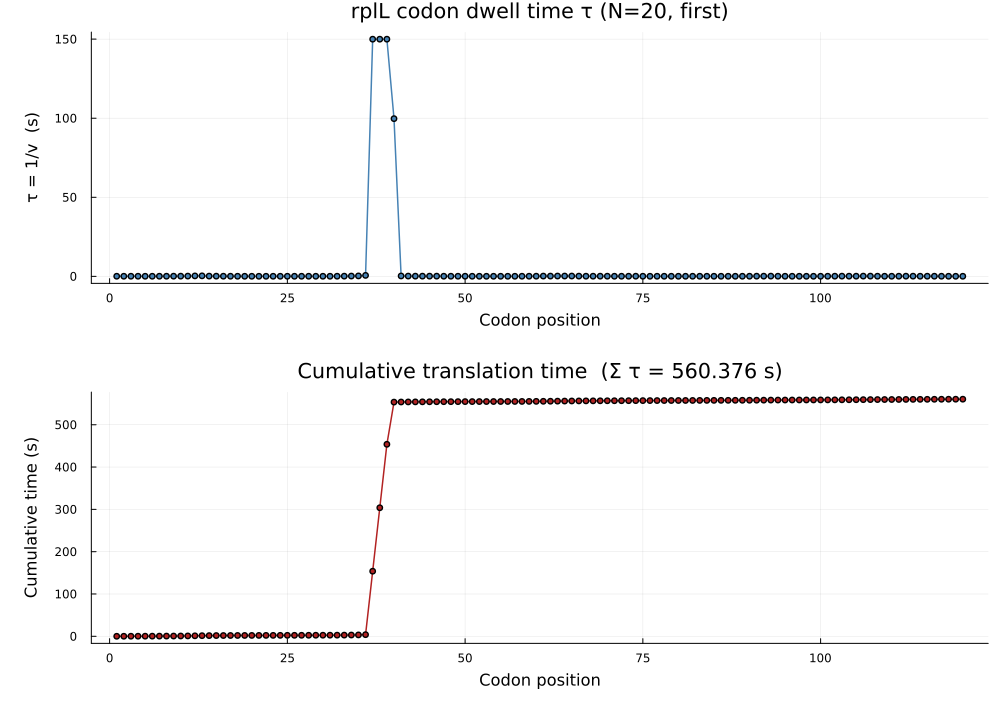

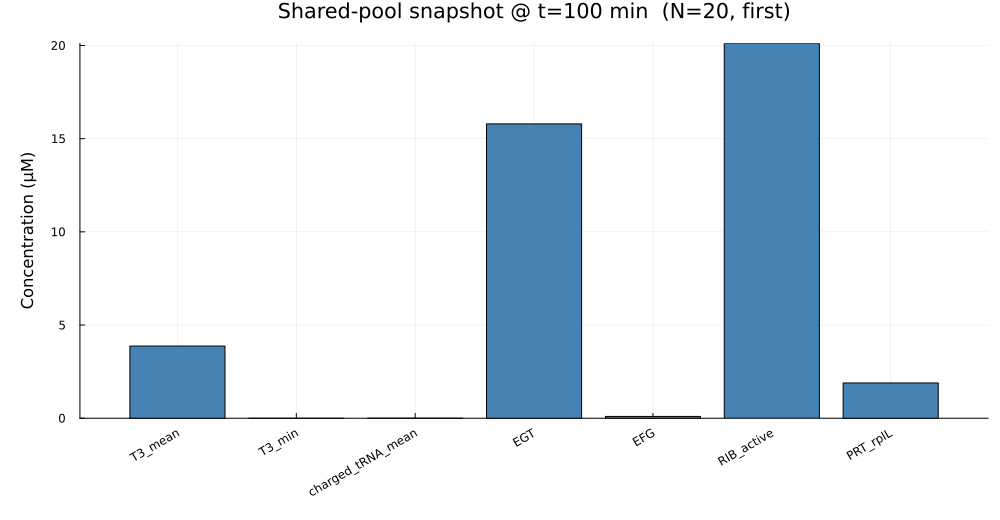

In [ ]:
# ============================================================================
# Main run: rplL + N background genes
#
# Steps (this cell):
#   1. Set the knobs below
#   2. Load FASTA + pick N background genes
#   3. Split the fixed mRNA budget (rplL share vs background)
#   4. call_model → integrate ODE to t_sample
#   5. Write CSVs / figures under data/output/ (tagged N*_mode_*)
#
# Knobs you usually change:
#   N_current          — number of background genes (e.g. 5, 10, 15, 20, 25)
#   bg_selection_mode  — :first  or  :codon_balanced
#   fasta_filename     — FASTA in data/sequences/ (e.g. bg_safe_20.fa)
#   m_total, f_rplL    — total mRNA (µM) and rplL share of that budget
#   primary_gene       — gene of interest (default "rplL")
#   t_sample           — snapshot time (min)
#   spindler_scale     — V_IN_70SIC / IF2D / ARS / Rib / EF / tRNA scales
#   ode_abstol_run     — raise to 1e-4 if N is very small or very large and the solver struggles
#
# Typical paper sweep: re-run this cell with N_current = 5, 10, 15, 20, 25
# ============================================================================

# ─── User-facing knobs ─────────────────────────────────────────────────────────
N_current         = 20                       # ← set to 10, 20, 30, 40, 50 and re-run; all outputs are tagged per N
bg_selection_mode = :first                   # :first reproduces the canonical spindler_rplL_N*_first_* runs | :codon_balanced also available
m_total           = 2.86                     # µM, total mRNA budget (matches rplL+3-RTS cell)
f_rplL            = 0.46 # 0.3 Old           # rplL share of the budget
t_sample          = 100.0                    # min, ODE snapshot time
primary_gene      = "rplL"
fasta_filename    = "bg_safe_20.fa"  # under data/sequences/
timeout_run_sec   = 600 * 60                 # 3 h cap for the 100-min run at run-I scales (see runs_summary.md)
ode_reltol_run    = 1e-8
# atol U-shaped ladder (runs_summary.md): N<=10 -> 1e-4, 15<=N<=45 -> 1e-5, N>=50 -> 1e-4
ode_abstol_run    =  1e-5 #(N_current <= 10 || N_current >= 50) ? 1e-4 #<--- change for N=50
ode_maxiters_run  = 5_000_000
ode_bottleneck_topk = 15                     # top-k states printed by ode_bottleneck_report

# ─── Stall freezing (see src/stall_freeze.jl) ──────────────────────────────────
# Off by default, so leaving these alone reproduces every published run exactly.
# When on, a background gene whose cognate T3 pool has collapsed AND whose
# ribosomes have stopped moving is latched frozen: its state (and therefore its
# sequestered ribosomes and mRNA) is held, and its stiff block leaves the
# integration. primary_gene is always protected from freezing.
freeze_stalled_run   = false                 # ← set true to enable
stall_tau_s_run      = 100.0                 # s, per-codon dwell marking a hard stall
stall_pool_frac_run  = 0.01                  # freeze only if min cognate pool < frac * KM_T3j
stall_du_tol_run     = 1e-6                  # quasi-stationarity tolerance on d(ribosome)/dt
stall_check_min_run  = 1.0                   # sim-minutes between freeze checks

# Spindler-faithful scaling factors (match spindler_rts_comparison)
spindler_scale = txtl_types.make_scale(
    V_IN_70SIC_scale = 75.0,
    V_IN_IF2D_scale  = 2.0,
    ARS_scale        = 20.0 .* ones(20),
    Rib_scale        = 1.0,
    EF_scale         = 1, #
    tRNA_scale       = 1, #
)

# ─── Load FASTA and mRNA pool (candidate set construction) ─────────────────────
seqs_to_use_pool = (1, 2401)
mRNA_pool = to_DataFrame(readmatrix("../data/input/mRNA_concentrations.xlsx",
                                    "mRNA_concentration", "A1:B2402"))
mRNA_pool = filter(row -> isa(row.mRNA, Number), mRNA_pool)

seqs_all_fasta, _ = seqs_import_transcripts(fasta_filename, seqs_to_use_pool)
fasta_gene_set    = Set{String}(String.(keys(seqs_all_fasta)))

# Build the candidate set: genes present in BOTH the mRNA xlsx and the FASTA,
# excluding the primary gene. The xlsx order is used as a stable "all genes"
# iteration order; the selection algorithm chooses from this candidate pool.
candidate_pool = String[]
for i in 1:nrow(mRNA_pool)
    g = String(mRNA_pool.gene[i])
    g == primary_gene && continue
    g in fasta_gene_set || continue
    push!(candidate_pool, g)
end
@printf("Candidate pool: %d genes (in FASTA ∩ mRNA-xlsx, excluding %s)\n",
        length(candidate_pool), primary_gene)

# ─── Select N_current background genes by chosen mode ──────────────────────────
println("\n" * "─"^78)
println("  Background selection mode = :$(bg_selection_mode)   N_current = $N_current")
println("─"^78)

local_bg_list   = String[]
balance_summary = nothing   # for :codon_balanced this holds the NamedTuple result

if bg_selection_mode == :first
    local_bg_list = candidate_pool[1:min(N_current, length(candidate_pool))]
    println("First $(length(local_bg_list)) genes in mRNA-xlsx order:")
    println("  ", join(local_bg_list, ", "))

elseif bg_selection_mode == :codon_balanced
    println("Computing proteome-average aa fractions across all $(length(seqs_all_fasta)) FASTA genes…")
    balance_summary = codon_balanced_background_selection(
        seqs_all_fasta, candidate_pool, primary_gene, N_current;
        seed_with_primary = true, verbose = true)
    local_bg_list = balance_summary.selected

    println("\nFinal codon-balance audit (primary + $(length(local_bg_list)) background):")
    @printf("  L1 deviation from proteome avg = %.4f\n", balance_summary.final_dev_l1)
    @printf("  Max per-aa deviation           = %.2f%%  (X-percent tolerance metric)\n",
            balance_summary.final_dev_pct_max)
    println("  Per-aa fractions (selected vs proteome target):")
    @printf("    %-3s  %12s  %12s  %12s\n", "aa", "selected", "target", "Δ%")
    for k in 1:20
        sel = balance_summary.final_fractions[k]
        tgt = balance_summary.target[k]
        delta_pct = tgt > 0 ? 100.0 * (sel - tgt) / tgt : NaN
        @printf("    %-3s  %12.4f  %12.4f  %12.2f\n",
                string(AA20_LETTERS[k]), sel, tgt, delta_pct)
    end
else
    error("Unknown bg_selection_mode = $bg_selection_mode  (expected :first or :codon_balanced)")
end

# ─── Build heterologous block ──────────────────────────────────────────────────
m_rplL = m_total * f_rplL
m_bg   = N_current == 0 ? 0.0 : m_total * (1 - f_rplL) / N_current
het_genes = vcat([primary_gene], local_bg_list)
het_conc  = Dict{String,Float64}(primary_gene => m_rplL)
for g in local_bg_list
    het_conc[g] = m_bg
end

# Pre-flight diagnostic — state-vector size estimate.
bg_codon_lens = [haskey(seqs_all_fasta, g) ? length(seqs_all_fasta[g].Codon) : 0
                 for g in het_genes]
est_codon_states = sum(4 .+ bg_codon_lens)
total_mRNA       = m_rplL + N_current * m_bg
println("\nPre-flight:")
@printf("  n_seq          = %d  (1 primary + %d background)\n",
        length(het_genes), length(local_bg_list))
@printf("  m_rplL         = %.4f µM   |   m_bg_each = %.4f µM   |   total_mRNA = %.4f µM\n",
        m_rplL, m_bg, total_mRNA)
@printf("  gene-block states ≈ %d  (+ ~340 shared metabolites)   |   timeout = %.0f s\n",
        est_codon_states, Float64(timeout_run_sec))
flush(stdout)

# ─── L3 helper: wall-time-bounded call (carried over from sweep cell) ──────────
function _run_with_timeout(f, timeout_s::Real)
    ch = Channel{Any}(1)
    t_task = @async try
        put!(ch, (:ok, f()))
    catch e
        put!(ch, (:error, e))
    end
    t0 = time()
    while !istaskdone(t_task)
        if time() - t0 > timeout_s
            return (:timeout, nothing, time() - t0)
        end
        sleep(0.5)
    end
    elapsed = time() - t0
    status, payload = take!(ch)
    return (status, payload, elapsed)
end

# ─── Run the single integration (Tier-1 settings: static_EFs=true, 75pct=false) ─
println("\n" * "═"^78)
println("  Solving ODE for N_current = $N_current …")
println("═"^78)
mkpath("../data/output")
mkpath("../data/output/figures")

status, payload, elapsed = _run_with_timeout(timeout_run_sec) do
    call_model(fasta_filename, het_genes, 0;
        custom_scale   = spindler_scale,
        growth_rate    = 1,
        het_mRNA_conc  = het_conc,
        return_details = true,
        return_sol     = true,
        static_EFs     = true,
        spindler_75pct = false,
        ode_reltol     = ode_reltol_run,
        ode_abstol     = ode_abstol_run,
        ode_maxiters   = ode_maxiters_run,
        freeze_stalled        = freeze_stalled_run,
        stall_tau_s           = stall_tau_s_run,
        stall_pool_frac       = stall_pool_frac_run,
        stall_du_tol          = stall_du_tol_run,
        stall_check_every_min = stall_check_min_run)
end
@printf("\n  Wall time: %.1f s   →   task_status = %s\n", elapsed, status)
flush(stdout)

# ─── Status detection (mirrors the Tier-1 logic from the sweep cell) ───────────
effective_status  = "ok"
sol_t_end_min     = NaN
retcode_str       = "n/a"
eval_t_min        = t_sample
actual_state_size = est_codon_states
res               = nothing

if status == :error
    @warn "call_model threw" exception = payload
    effective_status = "error"
elseif status == :timeout
    @warn "call_model exceeded timeout_run_sec" timeout_s = timeout_run_sec elapsed_s = round(elapsed, digits=1)
    effective_status = "timeout"
else
    res = payload
    actual_state_size = length(res.sol.u[end])
    sol_t_end_min     = float(res.sol.t[end])
    retcode_str       = string(res.sol.retcode)
    if !successful_retcode(res.sol)
        effective_status = "solver_failed"
        @warn "Solver returned non-success retcode" retcode = retcode_str sol_t_end_min = sol_t_end_min
    elseif sol_t_end_min < t_sample - 1e-9
        effective_status = "incomplete"
        @warn "Solver succeeded but stopped before t_sample" sol_t_end_min = sol_t_end_min t_sample = t_sample
    end
    eval_t_min = min(t_sample, sol_t_end_min)
end

# ─── Evaluate metrics + bottleneck report (if any integrated time was reached) ─
sp   = nothing
diag = nothing

if res !== nothing && eval_t_min > res.sol.t[1]
    sp   = spindler_codon_translation_time(res.sol, res.p, primary_gene;
                                           t_sample = eval_t_min)
    diag = collect_pool_diagnostics(res.sol, res.p, eval_t_min;
                                    primary_gene = primary_gene)

    @printf("\n  rplL total time = %.4f s   |   mean v = %.4f codons/s   |   L = %d   |   state_size = %d\n",
            sp.total_time_s, sp.mean_v, sp.L, actual_state_size)
    @printf("  Mean T3 = %.4f µM   |   T3_min = %.4e µM   |   KM/T3 = %.4f   |   charged tRNA = %.4f µM\n",
            diag.T3_mean, diag.T3_min, diag.mean_sat, diag.charged_mean)
    @printf("  EGT = %.2f µM   |   EFG = %.2f µM   |   RIB_active = %.4f µM   |   PRT(rplL) = %.4f µM\n",
            diag.EGT, diag.EFG, diag.RIB_active, diag.PRT_primary)
    @printf("  Effective status: %s   |   eval_t = %.3f min   |   sol_t_end = %.3f min   |   retcode = %s\n",
            effective_status, eval_t_min, sol_t_end_min, retcode_str)

    # The actionable "which ODE/codon is the bottleneck?" report.
    ode_bottleneck_report(res, eval_t_min;
        primary_gene = primary_gene,
        top_k = ode_bottleneck_topk)
else
    @warn "No integrated time available — skipping metrics and bottleneck report" eval_t_min sol_t_end_min effective_status
end

# ─── Persist per-N outputs (tagged so 20/30/40/50 runs accumulate) ─────────────
mode_tag = string(bg_selection_mode)
tag      = "N$(N_current)_$(mode_tag)"

summary_row = (
    N                = N_current,
    selection_mode   = mode_tag,
    n_seq            = length(het_genes),
    status           = effective_status,
    ok               = effective_status == "ok",
    wall_time_s      = elapsed,
    est_codon_states = actual_state_size,
    m_rplL           = m_rplL,
    m_bg_each        = m_bg,
    total_mRNA       = total_mRNA,
    eval_t_min       = eval_t_min,
    sol_t_end_min    = sol_t_end_min,
    retcode          = retcode_str,
    rplL_total_time_s = sp === nothing ? NaN : sp.total_time_s,
    rplL_mean_v       = sp === nothing ? NaN : sp.mean_v,
    rplL_L            = sp === nothing ? 0   : sp.L,
    T3_mean           = diag === nothing ? NaN : diag.T3_mean,
    T3_min            = diag === nothing ? NaN : diag.T3_min,
    T3_max            = diag === nothing ? NaN : diag.T3_max,
    charged_tRNA_mean = diag === nothing ? NaN : diag.charged_mean,
    EGT               = diag === nothing ? NaN : diag.EGT,
    EFG               = diag === nothing ? NaN : diag.EFG,
    KM_T3j            = diag === nothing ? NaN : diag.KM_T3j,
    mean_sat          = diag === nothing ? NaN : diag.mean_sat,
    RIB_active        = diag === nothing ? NaN : diag.RIB_active,
    PRT_primary       = diag === nothing ? NaN : diag.PRT_primary,
    final_PRT         = res === nothing ? NaN : res.final_PRT,
    aa_balance_L1     = balance_summary === nothing ? NaN : balance_summary.final_dev_l1,
    aa_balance_pct_max = balance_summary === nothing ? NaN : balance_summary.final_dev_pct_max,
)
CSV.write("../data/output/spindler_rplL_$(tag)_summary.csv", DataFrame([summary_row]))

# Per-codon detail — same schema as the sweep cell, with an N column.
codon_rows = NamedTuple[]
if sp !== nothing
    cum = cumsum(sp.tau)
    for (j, t_cum) in enumerate(cum)
        push!(codon_rows, (N = N_current, codon = j, cum_time_s = t_cum,
                            tau_s = sp.tau[j], v_codons_s = sp.v_smooth[j]))
    end
end
CSV.write("../data/output/spindler_rplL_$(tag)_codon_detail.csv", DataFrame(codon_rows))

# ─── Cross-run elongation log (per-codon rows, appendable) ──────────────────
# One row per rplL codon, carrying run-level params so plot_cross_N.py can filter
# by (timestamp, N). Schema matches the existing elongation_rate_log.csv. Only
# :ok runs with a usable sp are appended.
elong_log_path = "../data/output/elongation_rate_log.csv"
run_ts = string(Dates.now())
if sp !== nothing && effective_status == "ok"
    cumE = cumsum(sp.tau)
    elong_rows = NamedTuple[]
    for j in 1:sp.L
        push!(elong_rows, (
            timestamp         = run_ts,
            N                 = N_current,
            n_seq             = length(het_genes),
            bg_mode           = mode_tag,
            primary_gene      = primary_gene,
            codon_pos         = j,
            tau_s             = sp.tau[j],
            v_smooth_cod_s    = sp.v_smooth[j],
            cum_time_s        = cumE[j],
            rplL_total_time_s = sp.total_time_s,
            rplL_mean_v_cs    = sp.mean_v,
            T3_min            = diag === nothing ? NaN : diag.T3_min,
            T3_mean           = diag === nothing ? NaN : diag.T3_mean,
            m_rplL            = m_rplL,
            m_bg_each         = m_bg,
            total_mRNA        = total_mRNA,
            V_IN_70SIC_scale  = spindler_scale.V_IN_70SIC_scale,
            V_IN_IF2D_scale   = spindler_scale.V_IN_IF2D_scale,
            ARS_scale         = first(spindler_scale.ARS_scale),
            tRNA_scale        = spindler_scale.tRNA_scale,
            EF_scale          = spindler_scale.EF_scale,
            Rib_scale         = spindler_scale.Rib_scale,
            ode_reltol        = ode_reltol_run,
            ode_abstol        = ode_abstol_run,
            t_sample_min      = t_sample,
            sol_t_end_min     = sol_t_end_min,
            wall_time_s       = elapsed,
        ))
    end
    let elong_exists = isfile(elong_log_path)
        CSV.write(elong_log_path, DataFrame(elong_rows);
                  append = elong_exists, writeheader = !elong_exists)
    end
    @printf("  Appended %d codon rows  →  %s\n", length(elong_rows), elong_log_path)
else
    @info "Elongation log NOT appended" reason = (sp === nothing ? "no sp (integration did not produce a usable sol)" : "effective_status=$(effective_status) — only :ok runs are logged")
end

# ─── Run-level summary log (cross-run, appendable) ──────────────────────────────
# One row per run with all params + key results + the 3 most-depleted T3 species
# at eval_t. Use this CSV for cross-N "limiting tRNA" plots, Στ vs N scatter,
# pool-stability vs N — anything where you want exactly one number per run.
run_summary_log_path = "../data/output/run_summary_log.csv"

# Extract the 3 most-depleted T3 (charged tRNA·EF-Tu·GTP) species at eval_t.
# Names: tags.species_and_sequences.Tag[idx.a1t:idx.y1t] (e.g. "a1t", "e2t", ...).
limiting_T3_name = ""
limiting_T3_uM   = NaN
second_T3_name   = ""
second_T3_uM     = NaN
third_T3_name    = ""
third_T3_uM      = NaN
if res !== nothing && eval_t_min > res.sol.t[1]
    try
        tags_run     = res.p.local_tags_list[1]
        t3_range     = tags_run.idx.a1t : tags_run.idx.y1t
        t3_names_run = String.(tags_run.species_and_sequences.Tag[t3_range])
        t3_vals_run  = Float64.(res.sol(eval_t_min)[t3_range])
        ord          = sortperm(t3_vals_run)   # ascending → most depleted first
        length(ord) >= 1 && (limiting_T3_name = t3_names_run[ord[1]]; limiting_T3_uM = t3_vals_run[ord[1]])
        length(ord) >= 2 && (second_T3_name   = t3_names_run[ord[2]]; second_T3_uM   = t3_vals_run[ord[2]])
        length(ord) >= 3 && (third_T3_name    = t3_names_run[ord[3]]; third_T3_uM    = t3_vals_run[ord[3]])
    catch e
        @warn "Failed to extract limiting T3 species" exception = e
    end
end

# ─── Stall-freeze outcome (all-defaults when freezing is off) ──────────────────
# frozen_genes / freeze_times are packed into single ';'-joined cells so the
# summary stays one row per run; split on ';' when reading back.
n_frozen_run              = 0
frozen_genes_run          = ""
freeze_times_run          = ""
freeze_codons_run         = ""
ribosomes_sequestered_run = 0.0
if res !== nothing && hasproperty(res, :freeze) && res.freeze !== nothing
    fr = res.freeze
    n_frozen_run              = fr.n_frozen
    frozen_genes_run          = join(fr.frozen_genes, ";")
    freeze_times_run          = join((string(round(x, digits=3)) for x in fr.freeze_times), ";")
    freeze_codons_run         = join(fr.freeze_codons, ";")
    ribosomes_sequestered_run = fr.ribosomes_sequestered
end

run_summary_row = (
    timestamp         = string(Dates.now()),
    N                 = N_current,
    bg_mode           = mode_tag,
    primary_gene      = primary_gene,
    status            = effective_status,
    wall_time_s       = elapsed,
    eval_t_min        = eval_t_min,
    sol_t_end_min     = sol_t_end_min,
    t_sample_min      = t_sample,
    rplL_total_time_s = sp === nothing ? NaN : sp.total_time_s,
    rplL_mean_v_cs    = sp === nothing ? NaN : sp.mean_v,
    rplL_L            = sp === nothing ? 0   : sp.L,
    T3_mean           = diag === nothing ? NaN : diag.T3_mean,
    T3_min            = diag === nothing ? NaN : diag.T3_min,
    T3_max            = diag === nothing ? NaN : diag.T3_max,
    charged_tRNA_mean = diag === nothing ? NaN : diag.charged_mean,
    EGT               = diag === nothing ? NaN : diag.EGT,
    EFG               = diag === nothing ? NaN : diag.EFG,
    RIB_active        = diag === nothing ? NaN : diag.RIB_active,
    PRT_rplL          = diag === nothing ? NaN : diag.PRT_primary,
    limiting_T3_name  = limiting_T3_name,
    limiting_T3_uM    = limiting_T3_uM,
    second_T3_name    = second_T3_name,
    second_T3_uM      = second_T3_uM,
    third_T3_name     = third_T3_name,
    third_T3_uM       = third_T3_uM,
    m_rplL            = m_rplL,
    m_bg_each         = m_bg,
    total_mRNA        = total_mRNA,
    n_seq             = length(het_genes),
    V_IN_70SIC_scale  = spindler_scale.V_IN_70SIC_scale,
    V_IN_IF2D_scale   = spindler_scale.V_IN_IF2D_scale,
    ARS_scale         = first(spindler_scale.ARS_scale),
    tRNA_scale        = spindler_scale.tRNA_scale,
    EF_scale          = spindler_scale.EF_scale,
    Rib_scale         = spindler_scale.Rib_scale,
    ode_reltol        = ode_reltol_run,
    ode_abstol        = ode_abstol_run,
    freeze_stalled        = freeze_stalled_run,
    stall_tau_s           = stall_tau_s_run,
    stall_pool_frac       = stall_pool_frac_run,
    n_frozen              = n_frozen_run,
    frozen_genes          = frozen_genes_run,
    freeze_times          = freeze_times_run,
    freeze_codons         = freeze_codons_run,
    ribosomes_sequestered = ribosomes_sequestered_run,
)
# Appending a row with more columns than the existing header would silently
# misalign every future read, so if the schema has changed we archive the old
# log and start a fresh one rather than corrupting it.
let summary_file_exists = isfile(run_summary_log_path)
    if summary_file_exists
        old_header = split(strip(readline(run_summary_log_path)), ',')
        if old_header != [string(k) for k in keys(run_summary_row)]
            archived = replace(run_summary_log_path, ".csv" => "_pre_freeze_schema.csv")
            mv(run_summary_log_path, archived; force = true)
            @info "run_summary_log schema changed; archived previous log" archived
            summary_file_exists = false
        end
    end
    CSV.write(run_summary_log_path, DataFrame([run_summary_row]);
              append = summary_file_exists, writeheader = !summary_file_exists)
end
@printf("  Appended run summary    →  %s\n", run_summary_log_path)
@printf("  Limiting tRNA at t=%.0f min: %s = %.4e µM   (2nd: %s = %.4e,  3rd: %s = %.4e)\n",
        eval_t_min, limiting_T3_name, limiting_T3_uM,
        second_T3_name, second_T3_uM, third_T3_name, third_T3_uM)

# Background-gene audit + per-aa balance (only meaningful for :codon_balanced).
bg_rows = NamedTuple[]
for (rank, g) in enumerate(local_bg_list)
    push!(bg_rows, (N = N_current, rank = rank, gene = g, mRNA_uM = m_bg))
end
CSV.write("../data/output/spindler_rplL_$(tag)_background_genes.csv", DataFrame(bg_rows))

if balance_summary !== nothing
    aa_rows = NamedTuple[]
    for k in 1:20
        sel = balance_summary.final_fractions[k]
        tgt = balance_summary.target[k]
        push!(aa_rows, (
            aa            = string(AA20_LETTERS[k]),
            selected_frac = sel,
            target_frac   = tgt,
            abs_delta     = abs(sel - tgt),
            pct_delta     = tgt > 0 ? 100.0 * (sel - tgt) / tgt : NaN))
    end
    CSV.write("../data/output/spindler_rplL_$(tag)_aa_balance.csv", DataFrame(aa_rows))
end

# ─── Plots (tagged with N so each run produces fresh files) ────────────────────
if sp !== nothing
    # Plot 1: rplL codon profile — τ (s) and cumulative time vs codon position.
    p_tau = plot(1:sp.L, sp.tau;
        marker = :circle, markersize = 3, linewidth = 1.5, color = :steelblue,
        xlabel = "Codon position", ylabel = "τ = 1/v  (s)",
        title  = @sprintf("%s codon dwell time τ (N=%d, %s)", primary_gene, N_current, mode_tag),
        legend = false,
        left_margin = 8Plots.mm, bottom_margin = 8Plots.mm)
    cum = cumsum(sp.tau)
    p_cum = plot(1:length(cum), cum;
        marker = :circle, markersize = 3, linewidth = 1.5, color = :firebrick,
        xlabel = "Codon position", ylabel = "Cumulative time (s)",
        title  = @sprintf("Cumulative translation time  (Σ τ = %.3f s)", sp.total_time_s),
        legend = false,
        left_margin = 8Plots.mm, bottom_margin = 8Plots.mm)
    p_profile = plot(p_tau, p_cum; layout = (2, 1), size = (1000, 720))
    savefig(p_profile, "../data/output/figures/spindler_rplL_$(tag)_codon_profile.png")
    display(p_profile)
end

if diag !== nothing
    # Plot 2: pool snapshot bar chart — single-run summary, comparable across N.
    pool_names = ["T3_mean", "T3_min", "charged_tRNA_mean", "EGT", "EFG",
                  "RIB_active", "PRT_rplL"]
    pool_vals  = [diag.T3_mean, diag.T3_min, diag.charged_mean, diag.EGT, diag.EFG,
                  diag.RIB_active, diag.PRT_primary]
    p_pool = bar(pool_names, pool_vals;
        title = @sprintf("Shared-pool snapshot @ t=%.0f min  (N=%d, %s)",
                         eval_t_min, N_current, mode_tag),
        ylabel = "Concentration (µM)",
        xrotation = 30, legend = false, color = :steelblue, size = (1000, 520),
        left_margin = 8Plots.mm, bottom_margin = 12Plots.mm, top_margin = 5Plots.mm)
    savefig(p_pool, "../data/output/figures/spindler_rplL_$(tag)_pool_snapshot.png")
    display(p_pool)
end

if balance_summary !== nothing
    # Plot 3: per-aa balance — selected vs target — visualisation of the X% audit.
    aa_labels = String.(AA20_LETTERS)
    sel_v = balance_summary.final_fractions
    tgt_v = balance_summary.target
    p_aa = groupedbar(aa_labels, hcat(sel_v, tgt_v);
        label = ["selected" "proteome target"],
        bar_position = :dodge,
        ylabel = "Fraction of total amino acids",
        title  = @sprintf("Codon-balance audit  (max |Δ|/target = %.2f%%, N=%d)",
                          balance_summary.final_dev_pct_max, N_current),
        legend = :topright, size = (1100, 480),
        left_margin = 8Plots.mm, bottom_margin = 8Plots.mm)
    savefig(p_aa, "../data/output/figures/spindler_rplL_$(tag)_aa_balance.png")
    display(p_aa)
end

# ─── Summary printout ──────────────────────────────────────────────────────────
println("\n" * "═"^78)
@printf("  N=%d  (%s)   →   status=%s   wall_time=%.1f s\n",
        N_current, mode_tag, effective_status, elapsed)
if sp !== nothing
    @printf("  rplL  total_time = %.4f s   |   mean v = %.4f codons/s\n",
            sp.total_time_s, sp.mean_v)
end
if diag !== nothing
    @printf("  T3_mean = %.4f µM   T3_min = %.4e µM   RIB_active = %.4f µM   PRT_rplL = %.4f µM\n",
            diag.T3_mean, diag.T3_min, diag.RIB_active, diag.PRT_primary)
end
if balance_summary !== nothing
    @printf("  aa-balance: L1 = %.4f   |   max |Δ|/target = %.2f%%\n",
            balance_summary.final_dev_l1, balance_summary.final_dev_pct_max)
end
println("\nSaved artifacts (tagged $(tag)):")
println("  ../data/output/spindler_rplL_$(tag)_summary.csv")
println("  ../data/output/spindler_rplL_$(tag)_codon_detail.csv")
println("  ../data/output/spindler_rplL_$(tag)_background_genes.csv")
balance_summary !== nothing && println("  ../data/output/spindler_rplL_$(tag)_aa_balance.csv")
sp   !== nothing && println("  ../data/output/figures/spindler_rplL_$(tag)_codon_profile.png")
diag !== nothing && println("  ../data/output/figures/spindler_rplL_$(tag)_pool_snapshot.png")
balance_summary !== nothing && println("  ../data/output/figures/spindler_rplL_$(tag)_aa_balance.png")
println("═"^78)
println("Next: bump  N_current  to 30, 40, 50 and re-run this cell.")


In [1]:
# Validation harness for the stall-freezing feature (see stall_freeze.jl).
# Standalone cell: safe to run on its own, and deliberately uses vf_-prefixed
# names so it cannot clobber the production globals defined in the cell above
# (spindler_scale, mRNA_pool, seqs_all_fasta, fasta_gene_set, candidate_pool).

# Re-included so edits to functions.jl / stall_freeze.jl are picked up without
# restarting the kernel. Expect "replacing module txtl_types" warnings; any
# objects built by the production cell above become stale, so re-run that cell
# before using its results again.
include("packages.jl")

vf_fasta   = "bg_safe_20.fa"
vf_primary = "rplL"
vf_m_total = 2.86
vf_f_rplL  = 0.46
vf_t_end   = 100.0          # min. Short smoke test; raise to 100.0 to reach the stall regime
vf_N_list  = [5]          # e.g. [5, 10, 15, 20, 25] for the full sweep (see cost note below)

# Cost: 2 solves for check 0, then 3 per N for checks 1-2, then 5 more for
# checks 3-4 -- all the non-per-N ones at vf_N_list[end]. So [5] is 10 solves
# and [5,10,15,20,25] is 22, with 7 of those at N=25.

vf_scale = txtl_types.make_scale(
	V_IN_70SIC_scale = 75.0, V_IN_IF2D_scale = 2.0,
	ARS_scale = 20.0 .* ones(20), Rib_scale = 1.0, EF_scale = 1, tRNA_scale = 1)

vf_mRNA = to_DataFrame(readmatrix("../data/input/mRNA_concentrations.xlsx",
                                  "mRNA_concentration", "A1:B2402"))
vf_mRNA = filter(row -> isa(row.mRNA, Number), vf_mRNA)
vf_seqs, _   = seqs_import_transcripts(vf_fasta, (1, 2401))
vf_gene_set  = Set{String}(String.(keys(vf_seqs)))

vf_pool = String[]
for i in 1:nrow(vf_mRNA)
	g = String(vf_mRNA.gene[i])
	(g == vf_primary || !(g in vf_gene_set)) && continue
	push!(vf_pool, g)
end

function vf_setup(N)
	bg     = vf_pool[1:min(N, length(vf_pool))]
	m_rplL = vf_m_total * vf_f_rplL
	m_bg   = N == 0 ? 0.0 : vf_m_total * (1 - vf_f_rplL) / N
	genes  = vcat([vf_primary], bg)
	conc   = Dict{String,Float64}(vf_primary => m_rplL)
	for g in bg; conc[g] = m_bg; end
	return genes, conc
end

# Every solve is wrapped in a timeout. A freeze event is a discontinuity in the
# right-hand side, so a badly-chosen threshold can send FBDF into unbounded step
# reduction; without this the cell silently runs for hours. A timed-out solve
# returns `nothing` and the checks below report it rather than blocking.
#
# Same @async structure as _run_with_timeout in the production cell. Note the
# orphaned task is NOT killed -- Julia cannot interrupt it -- so it keeps
# burning cores in the background and later solves in this cell will look
# slower than they really are. If anything times out, restart the kernel before
# trusting the wall-time numbers.
vf_timeout_s = 8 * 3600 

function vf_with_timeout(f, timeout_s)
	ch = Channel{Any}(1)
	t  = @async try put!(ch, (:ok, f())) catch e; put!(ch, (:error, e)) end
	t0 = time()
	while !istaskdone(t) && (time() - t0) < timeout_s
		sleep(0.5)
	end
	elapsed = time() - t0
	istaskdone(t) || return (:timeout, nothing, elapsed)
	status, payload = take!(ch)
	return (status, payload, elapsed)
end

# Returns (result_or_nothing, status, elapsed_s). stall_verbose defaults ON so
# the log always shows which gene froze, when, and how big the jump was.
run_case(N; freeze, tau_s = 100.0, pool_frac = 0.01, du_tol = 1e-6, tend = vf_t_end, verbose = true) = begin
	genes, conc = vf_setup(N)
	status, payload, elapsed = vf_with_timeout(vf_timeout_s) do
		call_model(vf_fasta, genes, 0;
			custom_scale = vf_scale, growth_rate = 1, het_mRNA_conc = conc,
			return_details = true, return_sol = true,
			static_EFs = true, spindler_75pct = false,
			t_end = tend, ode_reltol = 1e-8, ode_abstol = 1e-5, ode_maxiters = 5_000_000,
			freeze_stalled = freeze, stall_tau_s = tau_s, stall_verbose = verbose)
	end
	if status == :timeout
		@printf("  !! TIMEOUT after %.0f s  (N=%d, freeze=%s, tau_s=%.3g)\n", elapsed, N, freeze, tau_s)
		return (nothing, :timeout, elapsed)
	elseif status == :error
		@warn "run_case threw" exception = payload N = N freeze = freeze tau_s = tau_s
		return (nothing, :error, elapsed)
	end
	return (payload, :ok, elapsed)
end

# final_PRT of a run, or NaN if it timed out / threw.
prt(r) = r === nothing ? NaN : r.final_PRT
nfroz(r) = (r === nothing || r.freeze === nothing) ? 0 : r.freeze.n_frozen

banner(s) = println("\n", "="^78, "\n  ", s, "\n", "="^78)
reldiff(x, y) = (isfinite(x) && x != 0) ? abs(x - y) / abs(x) : abs(x - y)



println(" main simulation started ")
# Track A then B on ONE freeze-off solve. Nsens comes from vf_N_list above, not from Check 3.
Nsens = vf_N_list[end]
banner("Track A: freeze OFF  N=$(Nsens)  t_end=$(vf_t_end) min")
let N = Nsens
	r, st, elapsed = run_case(N; freeze = false, verbose = false)
	@printf("  status=%s  wall=%.0f s  PRT_rplL=%.6g\n", st, elapsed, prt(r))
	if r === nothing || r.sol === nothing || !SciMLBase.successful_retcode(r.sol)
		println("  FAIL  solve did not complete — A is not done until freeze-off finishes at t_end")
	else
		try
			diag = collect_pool_diagnostics(r.sol, r.p, min(vf_t_end, r.sol.t[end]); primary_gene = vf_primary)
			@printf("  T3_min=%.4e µM   T3_mean=%.4g µM   RIB_active=%.4g µM\n",
			        diag.T3_min, diag.T3_mean, diag.RIB_active)
			println(st == :ok ? "  PASS  freeze-off integration completed (A)" :
			                   "  FAIL  unexpected status $st")
		catch e
			@warn "Track A: pool diagnostics failed" exception = e
			println("  PASS  solve completed; diagnostics failed (see warn)")
		end
		# Track B: same trajectory — dwell vs protein, no extra solve and no freeze.
		banner("Track B: delay → protein  (same run, freeze still OFF)")
		try
			print_track_b_report(r.sol, r.p; primary_gene = vf_primary)
		catch e
			@warn "Track B: report failed" exception = e
		end
	end
end

banner("done") 




🔧 Julia started with 12 threads
 main simulation started 

  Track A: freeze OFF  N=5  t_end=100.0 min
Number of sequences: 6 (background_selection=first)

========== EF pool audit (literature bands: Tu/Rib ~5–9×, Ts/Rib ~1×, Tu/Ts ~5–9×, EF-G/Rib ~1.5–2.5×) ==========
  Eut (total EF-Tu, constant_vars[13])     = 224.14529514482248 µM
  Est (EF-Ts, constant_vars[14])          = 19.45182200314482 µM
  S50 (50S subunit, state after balance)  = 20.08605675055541 µM
  c_EFG_t (DAE total EF-G, parameters.jl) = 39.56753084105652 µM
  EFG+EGT+EGD (state after EF_balance!)   = 39.56753084105652 µM  (should ≈ c_EFG_t)
  Eut/S50      = 11.159248324767603   [~5–9]
  Est/S50      = 0.9684241284744427   [~~1]
  Eut/Est      = 11.523100258093274   [~5–9]
  c_EFG_t/S50  = 1.9699003807684856   [~1.5–2.5]
========== end EF pool audit ==========

  Solver: FBDF  rtol=1.0e-8  atol=1.0e-5  maxiters=5000000  (n_seq=6)
Integration completed!
  status=ok  wall=455 s  PRT_rplL=2.03302
  T3_min=-8.9715e-10 µM 

#### Subramaniam 2013 — YFP CDS only (CTG vs C1A vs CTA)

Same promoter/RBS (identical `V_IN` and `het_mRNA_conc`); only the YFP CDS changes. Leu-ARS is the charging proxy. Freeze off. Paper check: rich ≈ equal PRT; starved CTA ≪ CTG.

In [1]:
# Subramaniam 2013 — YFP CDS-only: CTG / C1A / CTA × Leu-ARS {1, 0.1}
# Same mRNA and initiation for all three; freeze off; n_seq = 1.
if !isdefined(Main, :call_model) || !isdefined(Main, :txtl_types)
    include(isfile("packages.jl") ? "packages.jl" : joinpath("src", "packages.jl"))
end
include(isfile("goodman_2013.jl") ? "goodman_2013.jl" : joinpath("src", "goodman_2013.jl"))
using Printf, DataFrames, CSV

function seq_dir()
    isdefined(Main, :sequence_data_dir) && return sequence_data_dir()
    for d in (pwd(), joinpath(pwd(), "src"))
        isfile(joinpath(d, "functions.jl")) && return normpath(joinpath(d, "..", "data", "sequences"))
    end
    return normpath(joinpath(pwd(), "data", "sequences"))
end

prim       = "rplL"
LEU_IDX    = 10
LEU_LEVELS = [1.0, 0.1]
m_reporter = 1.0
timeout_s  = 1800
ATOL0      = 1e-4
pnas_fasta = isfile(joinpath("data", "PNAS_2013", "sd02.txt")) ?
    joinpath("data", "PNAS_2013", "sd02.txt") :
    joinpath("src", "data", "PNAS_2013", "sd02.txt")
out_subdir = "pnas_yfp_cds_only"
csv_path   = joinpath(seq_dir(), "..", "output", "pnas_yfp_cds_only.csv")

recs = read_fasta_ordered(pnas_fasta)
getrec(p) = last(recs[findfirst(r -> startswith(first(r), p), recs)])
yfp0, yfp1 = getrec("yfp0"), getrec("yfp1")
cods0 = [yfp0[i:i+2] for i in 1:3:length(yfp0)]
cods1 = [yfp1[i:i+2] for i in 1:3:length(yfp1)]
sens_pos = findall(k -> cods0[k] != cods1[k], eachindex(cods0))
one_site = sens_pos[1]
cods_1 = copy(cods0); cods_1[one_site] = "CTA"
yfp_1cta = join(cods_1)
@printf("substituted sites: %s | C1A site: %d | yfp0=%d nt  yfp1=%d nt\n",
        string(sens_pos), one_site, length(yfp0), length(yfp1))

reporters = [
    ("CTG", yfp0,     Int[]),
    ("C1A", yfp_1cta, [one_site]),
    ("CTA", yfp1,     collect(sens_pos)),
]

_make_scale = txtl_types.make_scale
mk_scale(la) = (ars = ones(20); ars[LEU_IDX] = la; _make_scale(
    V_TC_scale=1.0, k_TLEmaxj_scale=1.0, V_IN_70SIC_scale=1.0, V_IN_IF2D_scale=1.0,
    Rib_scale=1.0, IF_scale=1.0, EF_scale=1.0, tRNA_scale=1.0,
    ARS_scale=ars, RibRecycling=0.0, V_mDeg_scale=0.0))

function write_one_gene_fa(path, name, seq)
    mkpath(dirname(path))
    open(path, "w") do io
        println(io, ">", name)
        s = uppercase(String(seq))
        for i in 1:70:length(s)
            println(io, s[i:min(i+69, end)])
        end
    end
    return path
end

function _run(f, ts)
    ch = Channel{Any}(1)
    t  = @async try; put!(ch, (:ok, f())); catch e; put!(ch, (:error, e)); end
    t0 = time()
    while !istaskdone(t)
        time()-t0 > ts && return (:timeout, nothing, time()-t0)
        sleep(0.5)
    end
    s, p = take!(ch)
    return (s, p, time()-t0)
end

function decode_pools(payload, gene, te)
    p = payload.p; si = _find_seq_index(p, gene); tg = p.local_tags_list[si]
    us = extract_u_sequence(payload.sol(te), p, si); ns = tg.num_species
    cC = tg.t3_Codon_struc * reshape(max.(us[1:ns], 0.0), 1, ns)'
    ci = tg.species_and_sequences.cod_idx
    poolof(target) = begin
        for (k, v) in ci; string(k) == target && return cC[v]; end
        return NaN
    end
    return (cta = poolof("CUA"), ctg = poolof("CUG"))
end

het_conc = Dict(prim => m_reporter)
mkpath(joinpath(seq_dir(), out_subdir))
mkpath(dirname(csv_path))
rows = NamedTuple[]

function run_yfp(label, cds, la, cta_sites)
    rel = joinpath(out_subdir, replace(label, r"[^A-Za-z0-9_]" => "_") * ".fa")
    write_one_gene_fa(joinpath(seq_dir(), rel), prim, cds)
    @printf("\n%-12s (Leu-ARS=%.3g) ", label, la); flush(stdout)
    status, payload, wall = _run(timeout_s) do
        call_model(rel, [prim], 0;
            custom_scale = mk_scale(la), growth_rate = 1.0, het_mRNA_conc = het_conc,
            return_details = true, return_sol = true, static_EFs = true, spindler_75pct = false,
            ode_reltol = 1e-8, ode_abstol = ATOL0, ode_maxiters = 5_000_000)
    end
    ok = status == :ok && payload !== nothing && successful_retcode(payload.sol)
    if !ok
        r = (label=label, leu_ars=la, PRT=NaN, fold_vs_CTG=NaN, RIB=NaN,
             cta_tau=NaN, cta_pool=NaN, T3_min=NaN, wall_s=wall, status=string(status))
        @printf("FAILED (%s) wall=%.0fs\n", status, wall)
        if status == :error
            showerror(stdout, payload); println(); flush(stdout)
        end
        push!(rows, r); return r
    end
    te = float(payload.sol.t[end])
    dg = collect_pool_diagnostics(payload.sol, payload.p, te; primary_gene=prim)
    sp = spindler_codon_translation_time(payload.sol, payload.p, prim; t_sample=te)
    dp = decode_pools(payload, prim, te)
    cs = filter(p -> p <= sp.L, cta_sites)
    cta_tau = isempty(cs) ? 0.0 : sum(sp.tau[cs])
    r = (label=label, leu_ars=la, PRT=dg.PRT_primary, fold_vs_CTG=NaN, RIB=dg.RIB_active,
         cta_tau=cta_tau, cta_pool=dp.cta, T3_min=dg.T3_min, wall_s=wall, status="ok")
    @printf("ok  PRT=%.4g  RIB=%.1f  ctaτ=%.3g  CTApool=%.3g  T3min=%.3g  wall=%.0fs\n",
            r.PRT, r.RIB, r.cta_tau, r.cta_pool, r.T3_min, r.wall_s)
    push!(rows, r); return r
end

for la in LEU_LEVELS, (rep, seq, cs) in reporters
    run_yfp(@sprintf("%s_%.3g", rep, la), seq, la, cs)
end

res = DataFrame(rows)
for la in LEU_LEVELS
    ctg = filter(r -> r.label == @sprintf("CTG_%.3g", la), res)
    isempty(ctg) && continue
    p_ctg = ctg.PRT[1]
    for i in 1:nrow(res)
        res.leu_ars[i] == la || continue
        res.fold_vs_CTG[i] = res.PRT[i] / p_ctg
    end
end
CSV.write(csv_path, res)
println("\nSaved → ", csv_path)
show(res, allcols=true); println()

println("\nPaper check (Subramaniam 2013 Fig. 1 — same promoter/RBS, CDS only):")
println("  rich (Leu-ARS=1):  PRT(CTG) ≈ PRT(C1A) ≈ PRT(CTA)")
println("  starved (0.1):    PRT(CTA)/PRT(CTG) ≪ 1; C1A in between")
for la in LEU_LEVELS
    sub = filter(r -> r.leu_ars == la, res)
    println("\n  Leu-ARS = ", la)
    for r in eachrow(sub)
        @printf("    %-8s  PRT=%8.4g  vs CTG = %6.3f  ctaτ=%.3g\n",
                r.label, r.PRT, r.fold_vs_CTG, r.cta_tau)
    end
end

println("\nStarved / rich PRT fold (same CDS):")
for (rep, _, _) in reporters
    rich = filter(r -> r.label == @sprintf("%s_1", rep), res)
    star = filter(r -> r.label == @sprintf("%s_0.1", rep), res)
    (isempty(rich) || isempty(star)) && continue
    @printf("  %-3s  PRT(0.1)/PRT(1) = %.3g\n", rep, star.PRT[1] / rich.PRT[1])
end


🔧 Julia started with 12 threads
substituted sites: [42, 44, 46, 53, 60, 64, 68] | C1A site: 42 | yfp0=717 nt  yfp1=717 nt

CTG_1        (Leu-ARS=1) Number of sequences: 1 (background_selection=first)

========== EF pool audit (literature bands: Tu/Rib ~5–9×, Ts/Rib ~1×, Tu/Ts ~5–9×, EF-G/Rib ~1.5–2.5×) ==========
  Eut (total EF-Tu, constant_vars[13])     = 224.14529514482248 µM
  Est (EF-Ts, constant_vars[14])          = 19.45182200314482 µM
  S50 (50S subunit, state after balance)  = 20.08605671156839 µM
  c_EFG_t (DAE total EF-G, parameters.jl) = 39.56753084105652 µM
  EFG+EGT+EGD (state after EF_balance!)   = 39.56753084105652 µM  (should ≈ c_EFG_t)
  Eut/S50      = 11.159248346427697   [~5–9]
  Est/S50      = 0.9684241303541532   [~~1]
  Eut/Est      = 11.523100258093274   [~5–9]
  c_EFG_t/S50  = 1.9699003845920608   [~1.5–2.5]
========== end EF pool audit ==========

  Solver: FBDF  rtol=1.0e-8  atol=0.0001  maxiters=5000000  (n_seq=1)
Integration completed!
ok  PRT=1.746  RIB=20

#### Reduced cell load (mini-transcriptome)

`reduced_cell_load()` builds ~20 genes with **skewed mRNA**: head = real high-expressors (xlsx µM), tail = lumped leftover proteome mass. Change concentrations with `n_head`, `n_tail`, `f_reporter`, `m_total`. Pass `cell.het_mRNA_conc` into `call_model`. This cell only builds the load — it does not integrate.

In [2]:
# Mini-transcriptome. Preferred: edit knobs in make_reduced_background.jl and run that script.
# This cell is the same API for interactive use. Production equal-m_bg N=20 cell is untouched.
#   n_head, n_tail, f_reporter, m_total, tail_mode — concentrations live only here / in the script.
# Wiring: call_model(yfp_fastas["CTG"], cell.het_genes, 0; het_mRNA_conc=cell.het_mRNA_conc, ...)
include("packages.jl")
if !isdefined(Main, :reduced_cell_load)
    include(isfile("reduced_cell_load.jl") ? "reduced_cell_load.jl" : joinpath("src", "reduced_cell_load.jl"))
end

cell = reduced_cell_load(
    n_head     = 5,
    n_tail     = 5,
    reporter   = "rplL",
    f_reporter = 0.05,
    m_total    = 2.86,
    tail_mode  = :codon_match,
)
yfp_fastas = write_yfp_background_fastas(cell)

# Handles used by later cells (YFP + background, Leu-ARS sweep):
reduced_fasta = cell.out_fasta
reduced_genes = cell.het_genes
reduced_conc  = cell.het_mRNA_conc
load_csv = "../data/output/reduced_cell_load.csv"
mkpath(dirname(load_csv))
CSV.write(load_csv, cell.df)
println("Wrote conc table → ", load_csv, "  n_seq=", length(reduced_genes))


🔧 Julia started with 12 threads
  Leu-RS: competitive (LEU_RS_COMPETITIVE=true)
reduced_cell_load
  source FASTA     = Ecoli_K12_MG1655_geneset_with_welch_2009.fa  (2320 genes with mRNA)
  n_head / n_tail  = 5 / 5    reporter = rplL    tail_mode = :codon_match
  m_reporter       = 0.1430 µM  (f_reporter = 0.050)
  m_head           = 0.0798 µM  (5 genes, xlsx values rescaled)
  m_tail (lumped)  = 2.6372 µM  (5 tracks carry the leftover proteome)
  note: tail µM per gene can exceed head — those tracks are bulk stand-ins,
        not the 10 lowest genes. Head stays the real highest individual CDSs.
  m_total          = 2.8600 µM    background CDS length ≈ 4084 codons
  change mRNA here: f_reporter, m_total, n_head, n_tail, mRNA_multiplier
  then pass cell.het_mRNA_conc into call_model(; het_mRNA_conc=...)
  expression-weighted Leu demand (background, no reporter):
    proteome  Leu flux = 243.666   CTG/Leu = 0.621   CTA/Leu = 0.022
    reduced   Leu flux = 161.130   CTG/Leu = 0.647   CTA/

#### 1B — one simulation at a time (reduced cell + YFP)

Uses the **current** 5+5 load: `reduced_yfp/bg_*.fa` + `data/output/reduced_cell_load.csv` (11 genes: rplL + lpp,rplE,rplU,rpmJ,tufA + alaS,oppB,ppc,tpx,acrB). Change **only** `lab` and `leu_ars`. Freeze off. Expect `n_seq = 11`.

In [ ]:
# 1B competitive Leu-RS — ONE solve. Do not include packages.jl here.
# Order: CTG/1 → C1A/1 → CTA/1 → CTG/0.1 → C1A/0.1 → CTA/0.1
lab     = "CTA"    # "CTG" | "C1A" | "CTA"
leu_ars = 0.1      # 1.0 = rich | 0.1 = starved

using Printf, CSV, DataFrames
isdefined(Main, :LEU_RS_COMPETITIVE) || error("run the packages cell first (need LEU_RS_COMPETITIVE)")
LEU_RS_COMPETITIVE || error("LEU_RS_COMPETITIVE is false")
@printf("LEU_RS_COMPETITIVE=%s\n", LEU_RS_COMPETITIVE)

load_csv = "../data/output/reduced_cell_load.csv"   # 11-gene 5+5 table — not a FASTA
out_csv  = "../data/output/reduced_yfp_leu_ars_competitive.csv"
rel_fa   = joinpath("reduced_yfp", "bg_$(lab).fa")
fa_path  = joinpath(sequence_data_dir(), rel_fa)

if isdefined(Main, :cell) && isdefined(Main, :yfp_fastas) && haskey(yfp_fastas, lab)
    genes = String.(cell.het_genes)
    conc  = cell.het_mRNA_conc
    rel_fa = yfp_fastas[lab]
    fa_path = joinpath(sequence_data_dir(), rel_fa)
else
    isfile(load_csv) || error("missing $load_csv — run the reduced_cell_load cell")
    load = CSV.read(load_csv, DataFrame)
    hasproperty(load, :gene) || error("$load_csv has no :gene column (do not point load_csv at a FASTA)")
    genes = String.(load.gene)
    conc  = Dict{String,Float64}(zip(String.(load.gene), Float64.(load.m_assigned)))
end
reporter = genes[1]
isfile(fa_path) || error("Missing $fa_path — run the reduced_cell_load cell to write YFP FASTAs")
fa_genes = String[String(split(chop(ln; head=1, tail=0))[1]) for ln in eachline(fa_path) if startswith(ln, ">")]
fa_genes == genes || error("FASTA genes $(fa_genes) != conc table $(genes) — re-run reduced_cell_load then this cell")

cta_sites = Dict("CTG" => Int[], "C1A" => [42], "CTA" => [42, 44, 46, 53, 60, 64, 68])
haskey(cta_sites, lab) || error("lab must be CTG, C1A, or CTA")
LEU_IDX = findfirst(==('L'), AA20_LETTERS)
ars = ones(20); ars[LEU_IDX] = leu_ars
scale1 = txtl_types.make_scale(
    V_TC_scale=1.0, k_TLEmaxj_scale=1.0, V_IN_70SIC_scale=1.0, V_IN_IF2D_scale=1.0,
    Rib_scale=1.0, IF_scale=1.0, EF_scale=1.0, tRNA_scale=1.0,
    ARS_scale=ars, RibRecycling=0.0, V_mDeg_scale=0.0)

@printf("1B single  lab=%s  Leu-ARS=%.3g  n_seq=%d  m_reporter=%.4f µM  fasta=%s\n",
        lab, leu_ars, length(genes), conc[reporter], rel_fa)
@printf("  next: set lab/leu_ars as below, re-run this cell only\n")
println("       CTG,1.0  |  C1A,1.0  |  CTA,1.0  |  CTG,0.1  |  C1A,0.1  |  CTA,0.1")
flush(stdout)

t0 = time()
payload = call_model(rel_fa, genes, 0;
    custom_scale = scale1, growth_rate = 1.0, het_mRNA_conc = conc,
    return_details = true, return_sol = true, static_EFs = true, spindler_75pct = false,
    freeze_stalled = false, t_end = 100.0,
    ode_reltol = 1e-8, ode_abstol = 1e-4, ode_maxiters = 5_000_000)
wall = time() - t0
successful_retcode(payload.sol) || error("solve retcode = $(payload.sol.retcode)")

te = float(payload.sol.t[end])
dg = collect_pool_diagnostics(payload.sol, payload.p, te; primary_gene=reporter)
sp = spindler_codon_translation_time(payload.sol, payload.p, reporter; t_sample=te)
si = _find_seq_index(payload.p, reporter)
tg = payload.p.local_tags_list[si]
us = extract_u_sequence(payload.sol(te), payload.p, si)
cC = tg.t3_Codon_struc * reshape(max.(us[1:tg.num_species], 0.0), 1, tg.num_species)'
ci = tg.species_and_sequences.cod_idx
poolof(t) = (for (k, v) in ci; string(k) == t && return cC[v]; end; NaN)
cs = filter(p -> 1 <= p <= sp.L, cta_sites[lab])
cta_tau = isempty(cs) ? 0.0 : sum(sp.tau[cs])

@printf("  ok  PRT=%.4g  RIB=%.4g  ctaτ=%.3g  CTApool=%.3g  T3min=%.3g  wall=%.0fs\n",
        dg.PRT_primary, dg.RIB_active, cta_tau, poolof("CUA"), dg.T3_min, wall)

row = (label=lab, leu_ars=leu_ars, PRT=dg.PRT_primary, fold_vs_CTG=NaN,
       RIB=dg.RIB_active, cta_tau=cta_tau, cta_pool=poolof("CUA"), ctg_pool=poolof("CUG"),
       T3_min=dg.T3_min, wall_s=wall, n_seq=length(genes), status="ok")
prev = isfile(out_csv) ? CSV.read(out_csv, DataFrame) : DataFrame()
prev = filter(r -> !(String(r.label) == lab && isapprox(Float64(r.leu_ars), leu_ars; atol=1e-9)), prev)
append!(prev, DataFrame([row]); promote=true)
for la in unique(prev.leu_ars)
    hit = findfirst(i -> String(prev.label[i]) == "CTG" && isapprox(prev.leu_ars[i], la; atol=1e-9) &&
                         String(prev.status[i]) == "ok", 1:nrow(prev))
    hit === nothing && continue
    p_ctg = prev.PRT[hit]; p_ctg == 0 && continue
    for i in 1:nrow(prev)
        isapprox(prev.leu_ars[i], la; atol=1e-9) || continue
        String(prev.status[i]) == "ok" || continue
        prev.fold_vs_CTG[i] = prev.PRT[i] / p_ctg
    end
end
mkpath(dirname(out_csv))
CSV.write(out_csv, prev)
println("Saved → ", out_csv)
show(prev, allrows=true, allcols=true); println()


LEU_RS_COMPETITIVE=true
1B single  lab=C1A  Leu-ARS=0.1  n_seq=11  m_reporter=0.1430 µM  fasta=reduced_yfp\bg_C1A.fa
  next: set lab/leu_ars as below, re-run this cell only
       CTG,1.0  |  C1A,1.0  |  CTA,1.0  |  CTG,0.1  |  C1A,0.1  |  CTA,0.1
Number of sequences: 11 (background_selection=first)

========== EF pool audit (literature bands: Tu/Rib ~5–9×, Ts/Rib ~1×, Tu/Ts ~5–9×, EF-G/Rib ~1.5–2.5×) ==========
  Eut (total EF-Tu, constant_vars[13])     = 224.14529514482248 µM
  Est (EF-Ts, constant_vars[14])          = 19.45182200314482 µM
  S50 (50S subunit, state after balance)  = 20.08605671156839 µM
  c_EFG_t (DAE total EF-G, parameters.jl) = 39.56753084105652 µM
  EFG+EGT+EGD (state after EF_balance!)   = 39.56753084105652 µM  (should ≈ c_EFG_t)
  Eut/S50      = 11.159248346427697   [~5–9]
  Est/S50      = 0.9684241303541532   [~~1]
  Eut/Est      = 11.523100258093274   [~5–9]
  c_EFG_t/S50  = 1.9699003845920608   [~1.5–2.5]
========== end EF pool audit ==========

  Solver: FBD